Training data
Use the existing embeddings and aligned surface-fuel map from Ian's HDFS.
Start with one tile to check the alignment and prepare a small sample for Random Forest.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql.functions import expr, col
from pyspark.ml.linalg import Vectors
from sedona.spark import SedonaContext
print("Imports finished")

Imports finished


In [2]:
# Use my Spark cluster and Ian's shared data.
HDFS = "hdfs://sacramento.cs.colostate.edu:30141"
FOCO_FULL_FILE = f"{HDFS}/final/data/full_embed_tiles/"
TARGET_FILE = f"{HDFS}/final/data/surface_fuels_aligned.tif"

import os

os.environ["PYSPARK_PYTHON"] = sys.executable

config = (
    SedonaContext.builder()
    .master("spark://salt-lake-city.cs.colostate.edu:30216")
    .config("spark.cores.max", "2")
    .config("spark.executor.memory", "2g")
    .config("spark.pyspark.python", sys.executable)
    .config(
        "spark.jars.packages",
        "org.apache.sedona:sedona-spark-4.1_2.13:1.9.1,"
        "org.datasyslab:geotools-wrapper:1.9.1-33.5",
    )
    .config(
        "spark.jars.repositories",
        "https://artifacts.unidata.ucar.edu/repository/unidata-all",
    )
    .getOrCreate()
)
sd = SedonaContext.create(config)
print("Spark master:", sd.sparkContext.master)

https://artifacts.unidata.ucar.edu/repository/unidata-all added as a remote repository with the name: repo-1
:: loading settings :: url = jar:file:/usr/local/spark/4.1.1-bin-hadoop3/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /s/bach/g/under/lfuller8/.ivy2.5.2/cache
The jars for the packages stored in: /s/bach/g/under/lfuller8/.ivy2.5.2/jars
org.apache.sedona#sedona-spark-4.1_2.13 added as a dependency
org.datasyslab#geotools-wrapper added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-f9ba766e-d7db-4740-98ae-76ddb95843f3;1.0
	confs: [default]
	found org.apache.sedona#sedona-spark-4.1_2.13;1.9.1 in central
	found org.apache.sedona#sedona-common;1.9.1 in central
	found org.apache.commons#commons-math3;3.6.1 in local-m2-cache
	found org.locationtech.jts#jts-core;1.20.0 in local-m2-cache
	found org.wololo#jts2geojson;0.16.1 in central
	found org.locationtech.spatial4j#spatial4j;0.8 in central
	found org.data

Spark master: spark://salt-lake-city.cs.colostate.edu:30216


26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_geomfromwkb replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_geomfromwkb replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_asbinary replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_asbinary replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_setsrid replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_setsrid replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_srid replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_srid replaced a previously registered function.
26/11/16 11:51:05 WARN SimpleFunctionRegistry: The function st_geogfromwkb replaced 

Load one tile
Choose one embedding file and read its first 256x256 tile. Read the combined target as one raster so overlapping target tiles do not create duplicate rows.

In [3]:
# Find the first embedding file in HDFS.
jvm = sd.sparkContext._jvm
path = jvm.org.apache.hadoop.fs.Path(FOCO_FULL_FILE)
fs = path.getFileSystem(sd.sparkContext._jsc.hadoopConfiguration())
files = sorted(
    item.getPath().toString()
    for item in fs.listStatus(path)
    if item.isFile() and item.getPath().getName().lower().endswith((".tif", ".tiff"))
)
print("Number of embedding files:", len(files))
print("Selected file:", files[0])

Number of embedding files: 30
Selected file: hdfs://sacramento.cs.colostate.edu:30141/final/data/full_embed_tiles/2022_foco_bbox_full_cog_1_1.tif


In [4]:
feature_df = (
    sd.read.format("raster")
    .option("tileWidth", "256")
    .option("tileHeight", "256")
    .load(files[0])
    .where((col("x") == 0) & (col("y") == 0))
    .select(col("rast").alias("feature_raster"), "name", "x", "y")
    .limit(1)
)
target_df = (
    sd.read.format("binaryFile")
    .load(TARGET_FILE)
    .selectExpr("RS_FromGeoTiff(content) AS target_raster")
)

In [5]:
# Compare the existing pixel grids.
f = list(feature_df.selectExpr("RS_MetaData(feature_raster) AS meta").first().meta)
t = list(target_df.selectExpr("RS_MetaData(target_raster) AS meta").first().meta)
# Metadata: origin X/Y, width/height, scale X/Y, skew X/Y, SRID, bands, ...
print("Feature dimensions:", f[2:4])
print("Target dimensions:", t[2:4])
print("Feature bands:", int(f[9]))
print("Same CRS?", f[8] == t[8])
print("Same pixel size?", np.allclose(f[4:6], t[4:6]))

same_grid = f[8] == t[8] and np.allclose(f[4:8], t[4:8])
offset = np.array([(f[0] - t[0]) / t[4], (f[1] - t[1]) / t[5]])
aligned = same_grid and np.allclose(offset, np.round(offset), atol=1e-6, rtol=0)
print("Grids aligned?", bool(aligned))
assert aligned, "Check the pixel grids before continuing."
assert np.allclose(f[6:8], [0, 0]) and f[4] > 0 and f[5] < 0
covered = (
    f[0] >= t[0] - 1e-6
    and f[0] + f[2] * f[4] <= t[0] + t[2] * t[4] + 1e-6
    and f[1] <= t[1] + 1e-6
    and f[1] + f[3] * f[5] >= t[1] + t[3] * t[5] - 1e-6
)
print("Target covers tile?", covered)
assert covered, "The target does not cover this tile."

Feature dimensions: [256, 256]
Target dimensions: [5932, 4453]
Feature bands: 128
Same CRS? True
Same pixel size? True
Grids aligned? True
Target covers tile? True


Match the labels
Extract the target area matching this embedding tile. Nearest-neighbor sampling preserves the fuel class codes. Only this small pair is brought into Python.

In [6]:
aligned_df = feature_df.crossJoin(target_df).select(
    "name", "x", "y", "feature_raster",
    expr("RS_ReprojectMatch(target_raster, feature_raster, 'NearestNeighbor')")
        .alias("target_raster_aligned"),
)
pair = aligned_df.first()

# Masked conversion replaces raster NODATA with NaN.
embeddings = np.asarray(pair.feature_raster.as_numpy_masked())
labels = np.asarray(pair.target_raster_aligned.as_numpy_masked())
print("Embedding shape (bands, height, width):", embeddings.shape)
print("Target shape (bands, height, width):", labels.shape)
print("Shapes match?", embeddings.shape[1:] == labels.shape[1:])
assert embeddings.shape[0] == 128 and labels.shape[0] == 1
assert embeddings.shape[1:] == labels.shape[1:]
labels = labels[0]

Embedding shape (bands, height, width): (128, 256, 256)
Target shape (bands, height, width): (1, 256, 256)
Shapes match? True


In [7]:
# Remove missing embeddings and labels.
valid = np.all(np.isfinite(embeddings), axis=0) & np.isfinite(labels)
valid &= labels != 9999  # Missing-label code from Ian's notebook.
print("Any missing pixels?", bool(np.any(~valid)))
print("Valid pixels:", int(valid.sum()))
assert valid.any(), "No valid pixels in this tile."
assert np.all(labels[valid] == np.floor(labels[valid])), "Expected integer fuel codes."

codes, counts = np.unique(labels[valid].astype(int), return_counts=True)
print("Fuel codes:", codes)
print("Pixel counts:", counts)

Any missing pixels? False
Valid pixels: 65536
Fuel codes: [101 102 122 142 144 147 157 171 191 916 932 941 942 943 944]
Pixel counts: [   16  1742 19785   120   540  3788 23030 13129   504    16    88   394
  1740   108   536]


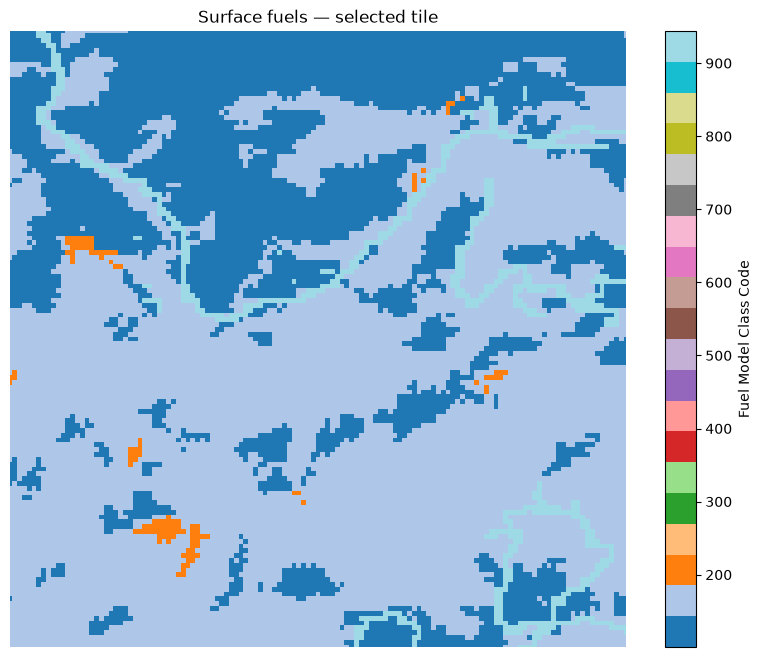

In [8]:
# What does the target patch look like?
plt.figure(figsize=(10, 8))
plt.imshow(np.ma.masked_where(~valid, labels), cmap="tab20", interpolation="nearest")
plt.title("Surface fuels — selected tile")
plt.colorbar(label="Fuel Model Class Code")
plt.axis("off")
plt.show()

Prepare sample rows
Each row contains a pixel's 128 embedding values and its original fuel code. Keep tile and pixel IDs so locations can be tracked. Start with up to 2,048 pixels to check the table.

In [9]:
pixel_rows, pixel_cols = np.where(valid)
rng = np.random.default_rng(42)
selected = np.sort(rng.choice(len(pixel_rows), min(2048, len(pixel_rows)), replace=False))
tile_id = f"{pair.name}:{pair.x}:{pair.y}"

rows = []
for i in selected:
    r, c = int(pixel_rows[i]), int(pixel_cols[i])
    rows.append((
        tile_id, r, c,
        Vectors.dense(embeddings[:, r, c].astype(float)),
        int(labels[r, c]),
    ))

training_df = sd.createDataFrame(
    rows, ["tile_id", "pixel_row", "pixel_col", "features", "fuel_code"]
)
training_df.printSchema()
training_df.show(5, truncate=40)

root
 |-- tile_id: string (nullable = true)
 |-- pixel_row: long (nullable = true)
 |-- pixel_col: long (nullable = true)
 |-- features: vector (nullable = true)
 |-- fuel_code: long (nullable = true)



26/11/16 11:51:41 WARN TaskSetManager: Stage 8 contains a task of very large size (1203 KiB). The maximum recommended task size is 1000 KiB.
[Stage 8:>                                                          (0 + 1) / 1]

+-----------------------------------+---------+---------+----------------------------------------+---------+
|                            tile_id|pixel_row|pixel_col|                                features|fuel_code|
+-----------------------------------+---------+---------+----------------------------------------+---------+
|2022_foco_bbox_full_cog_1_1.tif:0:0|        0|       78|[0.9734251499176025,0.126968502998352...|      122|
|2022_foco_bbox_full_cog_1_1.tif:0:0|        0|       98|[0.9654281139373779,-0.29453739523887...|      122|
|2022_foco_bbox_full_cog_1_1.tif:0:0|        0|      105|[0.820004940032959,-0.152559056878089...|      122|
|2022_foco_bbox_full_cog_1_1.tif:0:0|        0|      106|[0.7431102395057678,-0.22293308377265...|      122|
|2022_foco_bbox_full_cog_1_1.tif:0:0|        0|      146|[0.5339567065238953,-0.51488679647445...|      122|
+-----------------------------------+---------+---------+----------------------------------------+---------+
only showing top 5 

In [10]:
# Check the sample table.
print("Sample rows:", training_df.count())
print("Features per pixel:", len(rows[0][3]))
print("All vectors have 128 features?", all(len(row[3]) == 128 for row in rows))
print("Unique pixels?", len({(row[0], row[1], row[2]) for row in rows}) == len(rows))
training_df.groupBy("fuel_code").count().orderBy("fuel_code").show()

26/11/16 11:51:47 WARN TaskSetManager: Stage 9 contains a task of very large size (1203 KiB). The maximum recommended task size is 1000 KiB.
26/11/16 11:51:49 WARN TaskSetManager: Stage 12 contains a task of very large size (1203 KiB). The maximum recommended task size is 1000 KiB.


Sample rows: 2048
Features per pixel: 128
All vectors have 128 features? True
Unique pixels? True
+---------+-----+
|fuel_code|count|
+---------+-----+
|      102|   61|
|      122|  624|
|      142|    5|
|      144|   12|
|      147|  115|
|      157|  724|
|      171|  409|
|      191|   17|
|      916|    1|
|      932|    1|
|      941|   12|
|      942|   46|
|      943|    2|
|      944|   19|
+---------+-----+



Save samples from all tiles
Now use Spark workers to prepare samples across all embedding files. Keep up to 2,048 valid pixels per 256x256 tile. This is a sampled dataset for model development, not every pixel in the region. Rare classes may be absent from a tile's sample.

The code reads Ian's data and writes a new run folder in Liam's HDFS. Geographic splits and the fuel-code-to-label mapping are still needed before model evaluation. Do not use a random pixel split.

In [11]:
from datetime import datetime, timezone
from uuid import uuid4
import hashlib
from pyspark.sql.functions import broadcast, countDistinct
from pyspark.sql.types import (
    StructType, StructField, StringType, IntegerType, DoubleType,
)
from pyspark.ml.linalg import VectorUDT

MY_HDFS = "hdfs://salt-lake-city.cs.colostate.edu:30201"
SAMPLES_PER_TILE = 2048
SEED = 42
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid4().hex[:8]
OUTPUT = f"{MY_HDFS}/user/lfuller8/final/training_samples/{run_id}"
print("New output folder:", OUTPUT)

New output folder: hdfs://salt-lake-city.cs.colostate.edu:30201/user/lfuller8/final/training_samples/20261116T185152Z_6721736d


In [12]:
all_features = (
    sd.read.format("raster")
    .option("tileWidth", "256")
    .option("tileHeight", "256")
    .option("recursiveFileLookup", True)
    .load(FOCO_FULL_FILE)
    .select(col("rast").alias("feature_raster"), "name", "x", "y")
    .withColumn("grid", expr("RS_MetaData(feature_raster)"))
)
expected_tiles = all_features.count()
print("Tiles to process:", expected_tiles)
print("Maximum sample rows:", expected_tiles * SAMPLES_PER_TILE)

all_pairs = all_features.crossJoin(broadcast(target_df)).select(
    "name", "x", "y", "grid", "feature_raster",
    expr("RS_ReprojectMatch(target_raster, feature_raster, 'NearestNeighbor')")
        .alias("target_raster_aligned"),
)
target_grid = list(target_df.selectExpr("RS_MetaData(target_raster) AS meta").first().meta)

Tiles to process: 432
Maximum sample rows: 884736


Extract samples on the workers
Each worker checks a tile's grid, removes missing pixels, and produces feature rows. Global row/column numbers refer to the aligned target grid; easting/northing are pixel-center coordinates in its CRS.

In [13]:
def sample_partition(pairs):
    for tile in pairs:
        g, target = list(tile.grid), target_grid
        tile_id = f"{tile.name}:{tile.x}:{tile.y}"

        if g[8] != target[8] or not np.allclose(g[4:8], target[4:8]):
            raise ValueError(f"Different pixel grid: {tile_id}")
        if not np.allclose(g[6:8], [0, 0]) or g[4] <= 0 or g[5] >= 0:
            raise ValueError(f"Expected north-up grid: {tile_id}")
        offset = np.array([(g[0] - target[0]) / target[4],
                           (g[1] - target[1]) / target[5]])
        if not np.allclose(offset, np.round(offset), atol=1e-6, rtol=0):
            raise ValueError(f"Pixel origins do not align: {tile_id}")
        start_col, start_row = map(int, np.round(offset))
        if (start_col < 0 or start_row < 0
                or start_col + int(g[2]) > int(target[2])
                or start_row + int(g[3]) > int(target[3])):
            raise ValueError(f"Target does not cover tile: {tile_id}")

        features = np.asarray(tile.feature_raster.as_numpy_masked())
        target_values = np.asarray(tile.target_raster_aligned.as_numpy_masked())
        if features.shape != (128, int(g[3]), int(g[2])) or target_values.shape != (1, int(g[3]), int(g[2])):
            raise ValueError(f"Unexpected raster shape: {tile_id}")
        fuel = target_values[0]
        valid = np.all(np.isfinite(features), axis=0) & np.isfinite(fuel) & (fuel != 9999)
        rr, cc = np.where(valid)
        if not np.all(fuel[valid] == np.floor(fuel[valid])):
            raise ValueError(f"Non-integer fuel codes: {tile_id}")

        tile_seed = int.from_bytes(hashlib.sha256(f"{SEED}:{tile_id}".encode()).digest()[:8], "little")
        rng = np.random.default_rng(tile_seed)
        selected = np.sort(rng.choice(len(rr), min(SAMPLES_PER_TILE, len(rr)), replace=False))
        for i in selected:
            r, c = int(rr[i]), int(cc[i])
            yield (
                tile.name, tile_id, r, c, start_row + r, start_col + c,
                float(g[0] + (c + 0.5) * g[4]),
                float(g[1] + (r + 0.5) * g[5]),
                Vectors.dense(features[:, r, c].astype(float)), int(fuel[r, c]),
            )

In [15]:
schema = StructType([
    StructField("source_file", StringType(), False),
    StructField("tile_id", StringType(), False),
    StructField("pixel_row", IntegerType(), False),
    StructField("pixel_col", IntegerType(), False),
    StructField("global_row", IntegerType(), False),
    StructField("global_col", IntegerType(), False),
    StructField("easting", DoubleType(), False),
    StructField("northing", DoubleType(), False),
    StructField("features", VectorUDT(), False),
    StructField("fuel_code", IntegerType(), False),
])
all_training_df = sd.createDataFrame(all_pairs.rdd.mapPartitions(sample_partition), schema)

all_training_df.write.mode("errorifexists").parquet(f"{OUTPUT}/pixels")
print("Saved pixel samples:", f"{OUTPUT}/pixels")

Saved pixel samples: hdfs://salt-lake-city.cs.colostate.edu:30201/user/lfuller8/final/training_samples/20261116T185152Z_6721736d/pixels


Check the saved dataset
Read back Parquet rather than running raster extraction again. An empty tile can produce no sampled rows, so report how many tiles are represented. Check any coverage gap before training.

In [16]:
from pyspark.ml.functions import vector_to_array
from pyspark.sql.functions import size

saved_df = sd.read.parquet(f"{OUTPUT}/pixels")
stats = saved_df.agg(
    expr("count(*)").alias("rows"),
    countDistinct("tile_id").alias("tiles"),
    countDistinct("source_file").alias("files"),
    countDistinct("global_row", "global_col").alias("unique_pixels"),
).first()
invalid_vectors = saved_df.where(size(vector_to_array("features")) != 128).count()
print("Saved rows:", stats.rows)
print("Files represented:", stats.files, "of", len(files))
print("Tiles represented:", stats.tiles, "of", expected_tiles)
print("All tiles represented?", stats.tiles == expected_tiles)
print("All vectors have 128 features?", invalid_vectors == 0)
print("Unique pixel locations?", stats.rows == stats.unique_pixels)
assert stats.rows > 0 and invalid_vectors == 0
assert stats.rows == stats.unique_pixels, "Check overlapping source tiles."

class_counts = saved_df.groupBy("fuel_code").count().orderBy("fuel_code")
class_counts.show(100)
class_counts.write.mode("errorifexists").parquet(f"{OUTPUT}/class_counts")

Saved rows: 884736
Files represented: 30 of 30
Tiles represented: 432 of 432
All tiles represented? True
All vectors have 128 features? True
Unique pixel locations? True
+---------+------+
|fuel_code| count|
+---------+------+
|       99|  1517|
|      101| 72190|
|      102|251998|
|      104|   351|
|      121|  2978|
|      122|234371|
|      142|  2834|
|      144| 16286|
|      147| 22144|
|      157| 42068|
|      171| 25443|
|      182|     1|
|      183|     4|
|      191| 14597|
|      203|    47|
|      913|  4303|
|      915|     1|
|      916|  8769|
|      919| 10494|
|      931|   169|
|      932| 92874|
|      938|   808|
|      939|   123|
|      941| 35037|
|      942| 10769|
|      943|  1415|
|      944|  1818|
|      949| 13765|
|      989| 17562|
+---------+------+



In [18]:
settings = sd.createDataFrame([(
    FOCO_FULL_FILE, TARGET_FILE, int(target_grid[8]), SAMPLES_PER_TILE, SEED,
    int(expected_tiles), int(stats.tiles), int(stats.rows),
)], ["feature_source", "target_source", "epsg", "samples_per_tile", "seed",
     "input_tiles", "sampled_tiles", "sampled_rows"])
settings.coalesce(1).write.mode("errorifexists").json(f"{OUTPUT}/settings")

AnalysisException: [PATH_ALREADY_EXISTS] Path hdfs://salt-lake-city.cs.colostate.edu:30201/user/lfuller8/final/training_samples/20261116T185152Z_6721736d/settings already exists. Set mode as "overwrite" to overwrite the existing path. SQLSTATE: 42K04

Model-Development Next:

The /pixels is the saved sampled dataset. In another notebook we can load it with spark.read.parquet("path"). We will first agree on geographic split, map fuel codes. 